# 📉 Business Intelligence — Why Is Profit Falling Despite Higher Sales?
**Project:** DS_Day01_60 | **Industry:** Multi-Industry & Business Analytics | **Algorithm:** Random Forest

**Business problem:** Revenue grew by about 12% this year, yet profit fell. Management believes rising *operating costs* are the cause. We rebuild the profit equation from raw transactions and test that belief.

**Notebook flow**
1. Dataset creation (synthetic, 2 years: 2024 = last year, 2025 = this year)
2. Data cleaning & validation
3. Reconstructing the profit equation
4. Exploratory data analysis
5. Products, discounts, returns & logistics, regions & segments
6. What is driving the profit decline? (profit bridge)
7. Four visualisations
8. Random Forest model + evaluation
9. Key insights, action plan, conclusion

## 1. Setup & Synthetic Dataset Creation
No dataset was provided, so a realistic one is generated: **8,000 transactions over 2024–2025**, 8 products, 5 regions, 3 customer segments. In 2025 we deliberately build in deeper discounting (especially on Laptops, Smartphones and Monitors), higher logistics, return and marketing costs, and a mix shift towards low-margin products — the kind of hidden changes a real analyst would need to uncover.

`Discount` is stored as a **fraction of Sales** (0.10 = 10%), so `Revenue = Sales × (1 − Discount)`.

In [1]:
import pandas as pd
import numpy as np

np.random.seed(42)
n = 8000

In [2]:
products = ["Laptop", "Smartphone", "Monitor", "Tablet", "Camera", "Smartwatch", "Headphones", "Accessories"]
regions = ["North", "South", "East", "West", "Central"]
segments = ["Consumer", "Corporate", "Small Business"]

# Product characteristics: (base price, product cost as share of price, logistics cost per unit, base return probability)
prod = {
    "Laptop":      (1200, 0.78, 30, 0.08),
    "Smartphone":  (800,  0.76, 18, 0.09),
    "Monitor":     (350,  0.66, 35, 0.06),
    "Tablet":      (500,  0.62, 16, 0.07),
    "Camera":      (650,  0.58, 20, 0.05),
    "Smartwatch":  (300,  0.48, 10, 0.11),
    "Headphones":  (150,  0.40, 6,  0.08),
    "Accessories": (40,   0.28, 4,  0.04),
}
prod_p = [0.16, 0.18, 0.09, 0.12, 0.08, 0.11, 0.13, 0.13]

region_log = {"North": 1.00, "South": 1.00, "East": 1.20, "West": 1.05, "Central": 1.30}   # remote regions cost more to serve
seg_disc = {"Consumer": 0.02, "Corporate": 0.00, "Small Business": 0.01}

# Dates: 2025 has more transactions (volume growth), with a year-end seasonal peak
year = np.random.choice([2024, 2025], n, p=[0.458, 0.542])
month_w = np.array([0.8, 0.8, 0.9, 0.9, 1.0, 1.0, 0.9, 1.0, 1.0, 1.1, 1.3, 1.5])
month_w = month_w / month_w.sum()
month = np.random.choice(range(1, 13), n, p=month_w)
day = np.random.randint(1, 29, n)

df = pd.DataFrame({
    "Transaction_ID": [f"TXN{100000 + i}" for i in range(n)],
    "Date": pd.to_datetime(dict(year=year, month=month, day=day)),
    "Product": np.random.choice(products, n, p=prod_p),
    "Region": np.random.choice(regions, n, p=[0.22, 0.20, 0.18, 0.25, 0.15]),
    "Customer_Segment": np.random.choice(segments, n, p=[0.50, 0.30, 0.20]),
})

sales, disc, pcost, lcost, rcost, mkt = [], [], [], [], [], []
for _, r in df.iterrows():
    price, cost_ratio, log_unit, ret_rate = prod[r.Product]
    y25 = r.Date.year == 2025

    # Discount: deeper and more widespread in 2025 (Laptop/Smartphone/Monitor and the West region)
    base = 0.05 if not y25 else 0.07
    if y25 and r.Product in ("Laptop", "Smartphone", "Monitor"):
        base += 0.035
    if y25 and r.Region == "West":
        base += 0.02
    d = round(float(np.clip(np.random.normal(base + seg_disc[r.Customer_Segment], 0.04), 0, 0.40)), 2)

    # Units: deeper discounts lift quantity a little
    units = 1 + np.random.poisson(1.3 * (1 + 1.0 * d))
    gross = units * price * np.random.normal(1, 0.04)

    # Product cost (1.5% inflation in 2025)
    pc = units * price * cost_ratio * np.random.normal(1, 0.03) * (1.015 if y25 else 1.0)

    # Logistics cost (12% higher in 2025; East and Central are costlier)
    lc = log_unit * (units ** 0.9) * region_log[r.Region] * (1.12 if y25 else 1.0) * np.random.normal(1, 0.10)

    # Returns: more likely with deep discounts, and for consumers in 2025
    p_ret = ret_rate + 0.25 * d + (0.03 if (y25 and r.Customer_Segment == "Consumer") else 0)
    returned = np.random.random() < p_ret
    rc = (pc * np.random.uniform(0.15, 0.30) + 6 * units) if returned else 0.0

    # Marketing: ~2.2% of sales in 2024, ~2.7% in 2025 (more in the West)
    rate = np.random.normal(0.022, 0.005) if not y25 else np.random.normal(0.027, 0.006)
    if y25 and r.Region == "West":
        rate += 0.006
    mk = max(gross * rate, 0)

    sales.append(gross); disc.append(d); pcost.append(pc); lcost.append(lc); rcost.append(rc); mkt.append(mk)

df["Sales"] = np.round(sales, 2)
df["Discount"] = disc
df["Product_Cost"] = np.round(pcost, 2)
df["Logistics_Cost"] = np.round(lcost, 2)
df["Return_Cost"] = np.round(rcost, 2)
df["Marketing_Expenditure"] = np.round(mkt, 2)
df["Revenue"] = np.round(df["Sales"] * (1 - df["Discount"]), 2)
df["Profit"] = np.round(df["Revenue"] - df["Product_Cost"] - df["Logistics_Cost"]
                        - df["Return_Cost"] - df["Marketing_Expenditure"], 2)

print("Clean dataset generated:", df.shape)

Clean dataset generated: (8000, 13)


In [3]:
# Make the raw file "messy" like real company data: missing values, duplicates, inconsistent text, wrong profit entries
raw = df.copy()
ids = np.random.choice(raw.index, 150, replace=False)

raw.loc[ids[:40],   "Marketing_Expenditure"] = np.nan                      # missing marketing spend
raw.loc[ids[40:70], "Discount"] = np.nan                                    # missing discount
raw.loc[ids[70:120], "Region"] = raw.loc[ids[70:120], "Region"].apply(      # inconsistent text
    lambda x: np.random.choice([x.lower(), x.upper(), " " + x + " "]))
raw.loc[ids[120:130], "Profit"] = raw.loc[ids[120:130], "Profit"] * 10       # profit typos (extra zero)

raw = pd.concat([raw, raw.sample(40, random_state=1)], ignore_index=True)   # duplicated rows
raw["Date"] = raw["Date"].dt.strftime("%Y-%m-%d")                            # stored as text in the raw file

raw.to_csv("business_sales.csv", index=False)
print("Raw file saved -> business_sales.csv", raw.shape)
raw.head()

Raw file saved -> business_sales.csv (8040, 13)


,Transaction_ID,Date,Product,Region,Customer_Segment,Sales,Discount,Product_Cost,Logistics_Cost,Return_Cost,Marketing_Expenditure,Revenue,Profit
0,TXN100000,2024-10-17,Camera,West,Small Business,2508.63,0.00,1553.41,69.30,0.0,60.28,2508.63,825.64
1,TXN100001,2025-10-03,Laptop,South,Corporate,2407.67,0.14,1846.50,58.25,0.0,76.58,2070.60,89.27
2,TXN100002,2025-02-23,Camera,East,Corporate,1205.53,0.11,746.29,56.02,0.0,37.20,1072.92,233.41
3,TXN100003,2025-12-04,Laptop,West,Corporate,1105.73,0.17,981.16,33.09,0.0,34.80,917.76,-131.29
4,TXN100004,2024-08-02,Camera,North,Consumer,2654.91,0.12,1531.12,71.75,0.0,35.34,2336.32,698.11


## 2. Data Cleaning & Validation
We load the raw file and check: data types, missing values, duplicates, inconsistent labels, impossible values, and whether the recorded `Profit` really equals Revenue − all costs.

In [4]:
df = pd.read_csv("business_sales.csv")

print("Shape:", df.shape)
print("\nData types:\n", df.dtypes)
print("\nMissing values:\n", df.isnull().sum()[df.isnull().sum() > 0])
print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate Transaction_IDs:", df["Transaction_ID"].duplicated().sum())
print("\nRegion labels before cleaning:", sorted(df["Region"].unique()))

Shape: (8040, 13)

Data types:
 Transaction_ID            object
Date                      object
Product                   object
Region                    object
Customer_Segment          object
Sales                    float64
Discount                 float64
Product_Cost             float64
Logistics_Cost           float64
Return_Cost              float64
Marketing_Expenditure    float64
Revenue                  float64
Profit                   float64
dtype: object

Missing values:
 Discount                 30
Marketing_Expenditure    40
dtype: int64

Duplicate rows: 40
Duplicate Transaction_IDs: 40

Region labels before cleaning: [' Central ', ' East ', ' North ', ' South ', ' West ', 'CENTRAL', 'Central', 'EAST', 'East', 'NORTH', 'North', 'SOUTH', 'South', 'WEST', 'West', 'central', 'east', 'north', 'south', 'west']


In [5]:
# 1) Convert date column
df["Date"] = pd.to_datetime(df["Date"])

# 2) Fix inconsistent text labels
for col in ["Product", "Region", "Customer_Segment"]:
    df[col] = df[col].astype(str).str.strip().str.title()
print("Region labels after cleaning:", sorted(df["Region"].unique()))

# 3) Remove duplicate transactions
before = len(df)
df = df.drop_duplicates(subset="Transaction_ID").reset_index(drop=True)
print(f"Removed {before - len(df)} duplicate rows -> {len(df)} left")

# 4) Recover missing Discount from the data itself: Discount = 1 - Revenue / Sales
miss_disc = df["Discount"].isnull().sum()
df["Discount"] = df["Discount"].fillna((1 - df["Revenue"] / df["Sales"]).round(2))
print(f"Recovered {miss_disc} missing Discount values from Revenue and Sales")

Region labels after cleaning: ['Central', 'East', 'North', 'South', 'West']
Removed 40 duplicate rows -> 8000 left
Recovered 30 missing Discount values from Revenue and Sales


In [6]:
# 5) Validate the profit equation:  Profit = Revenue - Product_Cost - Logistics_Cost - Return_Cost - Marketing
cost_cols = ["Product_Cost", "Logistics_Cost", "Return_Cost", "Marketing_Expenditure"]

# a) Rows where every component is present but the recorded profit does not match -> data-entry errors
complete = df[cost_cols].notnull().all(axis=1)
calc_profit = df["Revenue"] - df[cost_cols].sum(axis=1)
mismatch = complete & ((df["Profit"] - calc_profit).abs() > 0.05)
print("Rows with a wrong recorded Profit:", mismatch.sum())
df.loc[mismatch, "Profit"] = calc_profit[mismatch].round(2)          # recompute from components

# b) Recover missing Marketing_Expenditure using the equation (Marketing = Revenue - other costs - Profit)
miss_mkt = df["Marketing_Expenditure"].isnull().sum()
df["Marketing_Expenditure"] = df["Marketing_Expenditure"].fillna(
    (df["Revenue"] - df["Product_Cost"] - df["Logistics_Cost"] - df["Return_Cost"] - df["Profit"]).round(2))
print(f"Recovered {miss_mkt} missing Marketing_Expenditure values using the profit equation")

# c) Impossible values
print("\nSales <= 0          :", (df["Sales"] <= 0).sum())
print("Discount outside 0-1:", ((df["Discount"] < 0) | (df["Discount"] > 1)).sum())
print("Negative costs      :", (df[cost_cols] < 0).any(axis=1).sum())
print("Revenue > Sales     :", (df["Revenue"] > df["Sales"] + 0.01).sum())

print("\nRemaining missing values:", df.isnull().sum().sum())
print("Final shape:", df.shape)

Rows with a wrong recorded Profit: 10
Recovered 40 missing Marketing_Expenditure values using the profit equation

Sales <= 0          : 0
Discount outside 0-1: 0
Negative costs      : 0
Revenue > Sales     : 0

Remaining missing values: 0
Final shape: (8000, 13)


In [7]:
# Helper columns used throughout the analysis
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["YearMonth"] = df["Date"].dt.to_period("M")
df["Discount_Amount"] = df["Sales"] * df["Discount"]
df["Contribution"] = df["Revenue"] - df["Product_Cost"] - df["Logistics_Cost"] - df["Return_Cost"]   # before marketing
df["Margin_%"] = df["Profit"] / df["Revenue"] * 100
df["Loss_Making"] = (df["Profit"] < 0).astype(int)
df.head()

,Transaction_ID,Date,Product,Region,Customer_Segment,Sales,Discount,Product_Cost,Logistics_Cost,Return_Cost,Marketing_Expenditure,Revenue,Profit,Year,Month,YearMonth,Discount_Amount,Contribution,Margin_%,Loss_Making
0,TXN100000,2024-10-17,Camera,West,Small Business,2508.63,0.00,1553.41,69.30,0.0,60.28,2508.63,825.64,2024,10,2024-10,0.0000,885.92,32.911988,0
1,TXN100001,2025-10-03,Laptop,South,Corporate,2407.67,0.14,1846.50,58.25,0.0,76.58,2070.60,89.27,2025,10,2025-10,337.0738,165.85,4.311311,0
2,TXN100002,2025-02-23,Camera,East,Corporate,1205.53,0.11,746.29,56.02,0.0,37.20,1072.92,233.41,2025,2,2025-02,132.6083,270.61,21.754651,0
3,TXN100003,2025-12-04,Laptop,West,Corporate,1105.73,0.17,981.16,33.09,0.0,34.80,917.76,-131.29,2025,12,2025-12,187.9741,-96.49,-14.305483,1
4,TXN100004,2024-08-02,Camera,North,Consumer,2654.91,0.12,1531.12,71.75,0.0,35.34,2336.32,698.11,2024,8,2024-08,318.5892,733.45,29.880753,0


## 3. Reconstructing the Profit Equation
From the raw columns, the company's profit is:

**Profit = Sales − Discounts − Product Cost − Logistics Cost − Return Cost − Marketing Expenditure**

where *Revenue = Sales − Discounts*. Below we prove the equation reproduces the recorded profit exactly, then build the full P&L for both years.

In [8]:
# Prove the equation reproduces the recorded profit
rebuilt = (df["Sales"] - df["Discount_Amount"] - df["Product_Cost"]
           - df["Logistics_Cost"] - df["Return_Cost"] - df["Marketing_Expenditure"])
print("Max difference between rebuilt and recorded Profit: {:.3f}".format((rebuilt - df["Profit"]).abs().max()))
print("Profit equation verified ✔" if (rebuilt - df["Profit"]).abs().max() < 0.05 else "Profit equation does NOT match ✘")

Max difference between rebuilt and recorded Profit: 0.005
Profit equation verified ✔


In [9]:
pl_cols = {"Sales": "Sales", "Discount_Amount": "Discounts", "Revenue": "Revenue", "Product_Cost": "Product Cost",
           "Logistics_Cost": "Logistics Cost", "Return_Cost": "Return Cost",
           "Marketing_Expenditure": "Marketing", "Profit": "Profit"}

pl = df.groupby("Year")[list(pl_cols)].sum().T
pl.index = [pl_cols[i] for i in pl.index]
pl["Change"] = pl[2025] - pl[2024]
pl["Change_%"] = pl["Change"] / pl[2024] * 100
print("=== PROFIT & LOSS ACCOUNT (totals) ===")
print(pl.round(1))

# Each line as % of gross Sales  (this is the "profit equation" in ratio form)
ratios = pl[[2024, 2025]].div(pl.loc["Sales", [2024, 2025]], axis=1) * 100
ratios["Change (pp)"] = ratios[2025] - ratios[2024]
print("\n=== EACH LINE AS % OF GROSS SALES ===")
print(ratios.round(2))

=== PROFIT & LOSS ACCOUNT (totals) ===
Year                 2024       2025    Change  Change_%
Sales           4797923.9  5672135.4  874211.5      18.2
Discounts        309060.2   638110.0  329049.8     106.5
Revenue         4488863.8  5034025.2  545161.4      12.1
Product Cost    3336872.9  3998723.2  661850.3      19.8
Logistics Cost   151385.2   197569.2   46184.0      30.5
Return Cost       75362.2   118185.3   42823.1      56.8
Marketing        104684.6   162195.5   57511.0      54.9
Profit           820559.0   557352.0 -263207.0     -32.1

=== EACH LINE AS % OF GROSS SALES ===
Year              2024    2025  Change (pp)
Sales           100.00  100.00         0.00
Discounts         6.44   11.25         4.81
Revenue          93.56   88.75        -4.81
Product Cost     69.55   70.50         0.95
Logistics Cost    3.16    3.48         0.33
Return Cost       1.57    2.08         0.51
Marketing         2.18    2.86         0.68
Profit           17.10    9.83        -7.28


In [10]:
# Test management's belief: "rising operating costs" (logistics + marketing) are the problem
op24 = pl.loc[["Logistics Cost", "Marketing"], 2024].sum()
op25 = pl.loc[["Logistics Cost", "Marketing"], 2025].sum()
print(f"Operating costs (logistics + marketing): {op24:,.0f} -> {op25:,.0f}  ({(op25/op24-1)*100:+.0f}%)")
print(f"...but as a share of Sales: {op24/pl.loc['Sales',2024]*100:.2f}% -> {op25/pl.loc['Sales',2025]*100:.2f}%")
print(f"\nProfit change: {pl.loc['Profit','Change']:,.0f}  ({pl.loc['Profit','Change_%']:.1f}%)")
print(f"Revenue change: {pl.loc['Revenue','Change']:,.0f}  ({pl.loc['Revenue','Change_%']:.1f}%)")
print("Profit margin (on revenue): {:.1f}% -> {:.1f}%".format(
    pl.loc['Profit',2024]/pl.loc['Revenue',2024]*100, pl.loc['Profit',2025]/pl.loc['Revenue',2025]*100))

Operating costs (logistics + marketing): 256,070 -> 359,765  (+40%)
...but as a share of Sales: 5.34% -> 6.34%

Profit change: -263,207  (-32.1%)
Revenue change: 545,161  (12.1%)
Profit margin (on revenue): 18.3% -> 11.1%


## 4. Exploratory Data Analysis (Descriptive Statistics)

In [11]:
print("=== DESCRIPTIVE STATISTICS ===")
print(df[["Sales", "Discount", "Revenue", "Product_Cost", "Logistics_Cost",
          "Return_Cost", "Marketing_Expenditure", "Profit", "Margin_%"]].describe().round(2).T)

print("\nTransactions per year:\n", df["Year"].value_counts().sort_index())
print("\nLoss-making transactions: {:.1f}%  (2024: {:.1f}% | 2025: {:.1f}%)".format(
    df["Loss_Making"].mean() * 100,
    df.loc[df.Year == 2024, "Loss_Making"].mean() * 100,
    df.loc[df.Year == 2025, "Loss_Making"].mean() * 100))
print("Transactions with a return: {:.1f}%".format((df["Return_Cost"] > 0).mean() * 100))

=== DESCRIPTIVE STATISTICS ===
                        count     mean      std      min     25%     50%  \
Sales                  8000.0  1308.76  1249.99    35.82  342.81  938.18   
Discount               8000.0     0.08     0.05     0.00    0.05    0.08   
Revenue                8000.0  1190.36  1128.81    31.33  312.14  861.32   
Product_Cost           8000.0   916.95   996.70    10.24  177.51  612.55   
Logistics_Cost         8000.0    43.62    36.02     3.11   16.63   34.14   
Return_Cost            8000.0    24.19   106.17     0.00    0.00    0.00   
Marketing_Expenditure  8000.0    33.36    34.62     0.28    8.94   22.58   
Profit                 8000.0   172.24   217.88 -2390.03   53.20  134.34   
Margin_%               8000.0    25.63    20.28   -43.75    9.83   24.73   

                           75%       max  
Sales                  1882.14  12246.58  
Discount                  0.12      0.26  
Revenue                1703.58  10164.66  
Product_Cost           1239.20   961

In [12]:
print("=== AVERAGE PER TRANSACTION BY YEAR ===")
print(df.groupby("Year")[["Sales", "Discount", "Revenue", "Product_Cost", "Logistics_Cost",
                          "Return_Cost", "Marketing_Expenditure", "Profit"]].mean().round(3).T)

print("\n=== CORRELATION WITH PROFIT MARGIN % ===")
print(df[["Discount", "Sales", "Logistics_Cost", "Return_Cost", "Marketing_Expenditure", "Margin_%"]]
      .corr()["Margin_%"].drop("Margin_%").round(3))

=== AVERAGE PER TRANSACTION BY YEAR ===
Year                       2024      2025
Sales                  1288.725  1326.195
Discount                  0.064     0.102
Revenue                1205.711  1176.999
Product_Cost            896.286   934.936
Logistics_Cost           40.662    46.193
Return_Cost              20.242    27.633
Marketing_Expenditure    28.118    37.923
Profit                  220.403   130.314

=== CORRELATION WITH PROFIT MARGIN % ===
Discount                -0.391
Sales                   -0.597
Logistics_Cost          -0.598
Return_Cost             -0.363
Marketing_Expenditure   -0.582
Name: Margin_%, dtype: float64


## 5. Deep-Dive Analysis

### 5.1 Products with high revenue but low margin

In [13]:
prod_tbl = df.groupby("Product").agg(
    Revenue=("Revenue", "sum"), Profit=("Profit", "sum"),
    Avg_Discount=("Discount", "mean"), Transactions=("Transaction_ID", "count"))
prod_tbl["Margin_%"] = prod_tbl["Profit"] / prod_tbl["Revenue"] * 100
prod_tbl["Revenue_Share_%"] = prod_tbl["Revenue"] / prod_tbl["Revenue"].sum() * 100
prod_tbl["Profit_Share_%"] = prod_tbl["Profit"] / prod_tbl["Profit"].sum() * 100

overall_margin = df["Profit"].sum() / df["Revenue"].sum() * 100
prod_tbl["High_Rev_Low_Margin"] = (prod_tbl["Revenue"] > prod_tbl["Revenue"].median()) & (prod_tbl["Margin_%"] < overall_margin)
print(f"Company margin: {overall_margin:.1f}%")
prod_tbl.sort_values("Revenue", ascending=False).round(2)

Company margin: 14.5%


,Revenue,Profit,Avg_Discount,Transactions,Margin_%,Revenue_Share_%,Profit_Share_%,High_Rev_Low_Margin
Product,,,,,,,,
Laptop,3399729.05,167592.67,0.10,1246,4.93,35.70,12.16,True
Smartphone,2652292.24,196201.26,0.09,1489,7.40,27.85,14.24,True
Tablet,972745.37,236320.83,0.08,895,24.29,10.21,17.15,False
Camera,920036.44,270903.00,0.08,638,29.44,9.66,19.66,False
Smartwatch,598882.65,233952.87,0.07,908,39.06,6.29,16.98,False
Monitor,530129.54,53914.55,0.09,685,10.17,5.57,3.91,False
Headphones,354203.50,168239.22,0.08,1061,47.50,3.72,12.21,False
Accessories,94870.18,50786.62,0.07,1078,53.53,1.00,3.69,False


In [14]:
# How each product changed from 2024 to 2025
py = df.pivot_table(index="Product", columns="Year", values=["Revenue", "Profit"], aggfunc="sum")
prod_chg = pd.DataFrame({
    "Revenue_24": py["Revenue"][2024], "Revenue_25": py["Revenue"][2025],
    "Profit_24": py["Profit"][2024], "Profit_25": py["Profit"][2025]})
prod_chg["Revenue_Growth_%"] = (prod_chg["Revenue_25"] / prod_chg["Revenue_24"] - 1) * 100
prod_chg["Profit_Change"] = prod_chg["Profit_25"] - prod_chg["Profit_24"]
prod_chg["Margin_24_%"] = prod_chg["Profit_24"] / prod_chg["Revenue_24"] * 100
prod_chg["Margin_25_%"] = prod_chg["Profit_25"] / prod_chg["Revenue_25"] * 100
prod_chg.sort_values("Profit_Change").round(1)

,Revenue_24,Revenue_25,Profit_24,Profit_25,Revenue_Growth_%,Profit_Change,Margin_24_%,Margin_25_%
Product,,,,,,,,
Laptop,1583104.5,1816624.6,159857.7,7735.0,14.8,-152122.7,10.1,0.4
Smartphone,1292447.6,1359844.6,151821.8,44379.5,5.2,-107442.3,11.7,3.3
Monitor,257614.8,272514.7,39078.5,14836.0,5.8,-24242.5,15.2,5.4
Headphones,170088.6,184114.8,83936.6,84302.6,8.2,365.9,49.3,45.8
Camera,429123.1,490913.4,134483.5,136419.5,14.4,1936.0,31.3,27.8
Accessories,43562.9,51307.3,24404.4,26382.2,17.8,1977.8,56.0,51.4
Tablet,440820.7,531924.7,115428.7,120892.1,20.7,5463.3,26.2,22.7
Smartwatch,272101.6,326781.1,111547.7,122405.2,20.1,10857.4,41.0,37.5


### 5.2 Effect of discounts on contribution
Contribution = Revenue − Product Cost − Logistics − Returns (before marketing). We group transactions into discount bands and compare profitability.

In [15]:
bins = [-0.001, 0.05, 0.10, 0.15, 0.20, 0.41]
labels = ["0-5%", "5-10%", "10-15%", "15-20%", "20%+"]
df["Discount_Band"] = pd.cut(df["Discount"], bins=bins, labels=labels)

disc_tbl = df.groupby("Discount_Band", observed=True).agg(
    Transactions=("Transaction_ID", "count"),
    Revenue=("Revenue", "sum"), Contribution=("Contribution", "sum"), Profit=("Profit", "sum"),
    Avg_Profit_per_Txn=("Profit", "mean"), Loss_Making_Share=("Loss_Making", "mean"))
disc_tbl["Contribution_Margin_%"] = disc_tbl["Contribution"] / disc_tbl["Revenue"] * 100
disc_tbl["Profit_Margin_%"] = disc_tbl["Profit"] / disc_tbl["Revenue"] * 100
disc_tbl["Loss_Making_Share"] *= 100
print(disc_tbl.round(2))

# Discount usage: 2024 vs 2025
print("\nAverage discount:  2024 = {:.1f}%   2025 = {:.1f}%".format(
    df.loc[df.Year == 2024, "Discount"].mean() * 100, df.loc[df.Year == 2025, "Discount"].mean() * 100))
print("Share of transactions with discount > 10%:  2024 = {:.1f}%   2025 = {:.1f}%".format(
    (df.loc[df.Year == 2024, "Discount"] > 0.10).mean() * 100, (df.loc[df.Year == 2025, "Discount"] > 0.10).mean() * 100))
print("Total discount given:  2024 = {:,.0f}   2025 = {:,.0f}".format(
    df.loc[df.Year == 2024, "Discount_Amount"].sum(), df.loc[df.Year == 2025, "Discount_Amount"].sum()))

               Transactions     Revenue  Contribution     Profit  \
Discount_Band                                                      
0-5%                   2222  2511888.00     625103.57  564399.70   
5-10%                  3201  3566926.59     706804.98  611376.90   
10-15%                 2016  2611622.12     302804.65  221416.49   
15-20%                  512   752681.33      18020.87   -8386.42   
20%+                     49    79770.93      -7942.98  -10895.65   

               Avg_Profit_per_Txn  Loss_Making_Share  Contribution_Margin_%  \
Discount_Band                                                                 
0-5%                       254.01               2.66                  24.89   
5-10%                      191.00               4.19                  19.82   
10-15%                     109.83              12.80                  11.59   
15-20%                     -16.38              45.31                   2.39   
20%+                      -222.36              85

In [16]:
# Discounts hurt some products far more than others: average profit margin by product and discount band
heat = df.pivot_table(index="Product", columns="Discount_Band", values="Margin_%", aggfunc="mean", observed=True)
print("Average profit margin (%) by product and discount band:")
print(heat.round(1))

# Break-even discount: first band where average profit margin turns negative
be = heat.apply(lambda row: next((c for c in heat.columns if row[c] < 0), "none"), axis=1)
print("\nFirst discount band with a negative average margin:")
print(be)

Average profit margin (%) by product and discount band:
Discount_Band  0-5%  5-10%  10-15%  15-20%  20%+
Product                                         
Accessories    56.6   52.8    49.4    47.1  45.2
Camera         33.3   28.7    24.4    21.7   NaN
Headphones     50.3   47.1    43.5    41.5  38.9
Laptop         12.6    7.1     0.8    -5.0 -15.2
Monitor        18.0   11.2     5.4    -3.0  -4.6
Smartphone     13.8    9.4     3.8    -4.1 -11.5
Smartwatch     41.9   38.4    35.0    29.8  33.1
Tablet         28.1   24.2    19.4    14.4  12.2

First discount band with a negative average margin:
Product
Accessories      none
Camera           none
Headphones       none
Laptop         15-20%
Monitor        15-20%
Smartphone     15-20%
Smartwatch       none
Tablet           none
dtype: object


### 5.3 Return and logistics costs

In [17]:
def cost_ratio(group):
    g = df.groupby(group).agg(Revenue=("Revenue", "sum"), Logistics=("Logistics_Cost", "sum"),
                              Returns=("Return_Cost", "sum"), Marketing=("Marketing_Expenditure", "sum"),
                              Return_Rate=("Return_Cost", lambda x: (x > 0).mean()))
    g["Logistics_%Rev"] = g["Logistics"] / g["Revenue"] * 100
    g["Returns_%Rev"] = g["Returns"] / g["Revenue"] * 100
    g["Marketing_%Rev"] = g["Marketing"] / g["Revenue"] * 100
    g["Return_Rate_%"] = g["Return_Rate"] * 100
    return g[["Logistics_%Rev", "Returns_%Rev", "Marketing_%Rev", "Return_Rate_%"]].round(2)

print("=== BY YEAR ===");    print(cost_ratio("Year"))
print("\n=== BY PRODUCT ==="); print(cost_ratio("Product").sort_values("Returns_%Rev", ascending=False))
print("\n=== BY REGION ===");  print(cost_ratio("Region").sort_values("Logistics_%Rev", ascending=False))
print("\n=== BY SEGMENT ===");  print(cost_ratio("Customer_Segment"))

=== BY YEAR ===
      Logistics_%Rev  Returns_%Rev  Marketing_%Rev  Return_Rate_%
Year                                                             
2024            3.37          1.68            2.33           9.70
2025            3.92          2.35            3.22          11.64

=== BY PRODUCT ===
             Logistics_%Rev  Returns_%Rev  Marketing_%Rev  Return_Rate_%
Product                                                                 
Smartphone             2.63          2.47            2.81          12.16
Smartwatch             3.81          2.22            2.77          16.30
Laptop                 2.93          2.17            2.83          10.67
Monitor               11.70          1.96            2.81          11.09
Accessories           11.34          1.86            2.76           7.98
Headphones             4.56          1.55            2.72          11.22
Tablet                 3.68          1.37            2.79           7.93
Camera                 3.49          1.09  

In [18]:
# Do discounts drive returns? Return rate by discount band
ret_by_disc = df.groupby("Discount_Band", observed=True)["Return_Cost"].apply(lambda x: (x > 0).mean() * 100).round(2)
print("Return rate (% of transactions) by discount band:\n", ret_by_disc)

Return rate (% of transactions) by discount band:
 Discount_Band
0-5%       9.59
5-10%     10.25
10-15%    11.71
15-20%    14.26
20%+      18.37
Name: Return_Cost, dtype: float64


### 5.4 Regions and customer segments

In [19]:
def yoy_table(group):
    t = df.pivot_table(index=group, columns="Year", values=["Revenue", "Profit"], aggfunc="sum")
    out = pd.DataFrame({
        "Revenue_Growth_%": (t["Revenue"][2025] / t["Revenue"][2024] - 1) * 100,
        "Profit_24": t["Profit"][2024], "Profit_25": t["Profit"][2025],
        "Profit_Change_%": (t["Profit"][2025] / t["Profit"][2024] - 1) * 100,
        "Margin_24_%": t["Profit"][2024] / t["Revenue"][2024] * 100,
        "Margin_25_%": t["Profit"][2025] / t["Revenue"][2025] * 100})
    out["Profit_Change"] = out["Profit_25"] - out["Profit_24"]
    return out.round(1)

print("=== REGIONS ==="); print(yoy_table("Region").sort_values("Profit_Change"))
print("\n=== CUSTOMER SEGMENTS ==="); print(yoy_table("Customer_Segment").sort_values("Profit_Change"))

=== REGIONS ===
         Revenue_Growth_%  Profit_24  Profit_25  Profit_Change_%  Margin_24_%  \
Region                                                                          
West                  5.1   204915.5   120031.1            -41.4         17.4   
North                13.1   182868.7   127371.5            -30.3         19.0   
East                 14.0   150587.4   102474.8            -31.9         17.9   
South                23.4   164574.2   124556.6            -24.3         20.0   
Central               7.1   117613.2    82918.0            -29.5         17.2   

         Margin_25_%  Profit_Change  
Region                               
West             9.7       -84884.4  
North           11.7       -55497.2  
East            10.7       -48112.6  
South           12.3       -40017.6  
Central         11.3       -34695.2  

=== CUSTOMER SEGMENTS ===
                  Revenue_Growth_%  Profit_24  Profit_25  Profit_Change_%  \
Customer_Segment                              

In [20]:
# 2025 profit margin by Region x Segment, and 2025 discount by Region x Segment
d25 = df[df.Year == 2025]
m25 = d25.pivot_table(index="Region", columns="Customer_Segment", values="Profit", aggfunc="sum") / \
      d25.pivot_table(index="Region", columns="Customer_Segment", values="Revenue", aggfunc="sum") * 100
print("2025 profit margin (%) — Region x Segment:"); print(m25.round(1))
print("\n2025 average discount (%) — Region x Segment:")
print((d25.pivot_table(index="Region", columns="Customer_Segment", values="Discount", aggfunc="mean") * 100).round(1))

2025 profit margin (%) — Region x Segment:
Customer_Segment  Consumer  Corporate  Small Business
Region                                               
Central               11.2       12.2            10.1
East                   9.5       11.4            12.7
North                 11.3       12.2            12.0
South                 10.9       14.1            12.9
West                   8.9        9.9            11.1

2025 average discount (%) — Region x Segment:
Customer_Segment  Consumer  Corporate  Small Business
Region                                               
Central               10.5        8.9             9.3
East                  10.8        8.9             9.1
North                 10.4        8.9             9.7
South                 10.5        8.4             9.3
West                  12.1       10.5            10.8


## 6. What Is Driving the Profit Decline? (Profit Bridge)
Because `Profit = Sales × (1 − d − c − l − r − m)` (d, c, l, r, m = discount, product cost, logistics, returns, marketing as a share of gross Sales), the change in profit from 2024 to 2025 splits **exactly** into:

- **Volume effect:** extra gross sales earning last year's margin (a positive push)
- **Margin-rate effects:** how much each cost ratio moved × this year's sales (discount, product cost, logistics, returns, marketing)

In [21]:
S24, S25 = pl.loc["Sales", 2024], pl.loc["Sales", 2025]
r24 = ratios[2024] / 100
r25 = ratios[2025] / 100          # ratios as fractions of gross Sales

margin24 = r24["Profit"]
bridge = {
    "Sales volume growth (at 2024 margin)": (S25 - S24) * margin24,
    "Higher discounts":         -(r25["Discounts"]      - r24["Discounts"])      * S25,
    "Product cost inflation": -(r25["Product Cost"] - r24["Product Cost"]) * S25,
    "Logistics cost":           -(r25["Logistics Cost"] - r24["Logistics Cost"]) * S25,
    "Return cost":              -(r25["Return Cost"]    - r24["Return Cost"])    * S25,
    "Marketing spend":          -(r25["Marketing"]      - r24["Marketing"])      * S25,
}
bridge = pd.Series(bridge)
profit_change = pl.loc["Profit", "Change"]
print("Profit 2024:", round(pl.loc["Profit", 2024]), "| Profit 2025:", round(pl.loc["Profit", 2025]))
print("Check: sum of effects = {:,.0f}  vs actual change = {:,.0f}\n".format(bridge.sum(), profit_change))

drivers = bridge.drop("Sales volume growth (at 2024 margin)")
summary = pd.DataFrame({"Effect_on_Profit": bridge.round(0),
                        "Share_of_margin_erosion_%": (drivers / drivers.sum() * 100).round(1)})
print(summary)

op_effect = bridge["Logistics cost"] + bridge["Marketing spend"]
print(f"\nManagement's 'operating costs' (logistics + marketing): {op_effect:,.0f}  "
      f"= {op_effect / drivers.sum() * 100:.0f}% of the margin erosion")
print(f"Discounts + product cost ratio: {bridge['Higher discounts'] + bridge['Product cost inflation']:,.0f}  "
      f"= {(bridge['Higher discounts'] + bridge['Product cost inflation']) / drivers.sum() * 100:.0f}% of the margin erosion")

Profit 2024: 820559 | Profit 2025: 557352
Check: sum of effects = -263,207  vs actual change = -263,207

                                      Effect_on_Profit  \
Higher discounts                             -272737.0   
Logistics cost                                -18601.0   
Marketing spend                               -38437.0   
Product cost inflation                        -53851.0   
Return cost                                   -29092.0   
Sales volume growth (at 2024 margin)          149511.0   

                                      Share_of_margin_erosion_%  
Higher discounts                                           66.1  
Logistics cost                                              4.5  
Marketing spend                                             9.3  
Product cost inflation                                     13.0  
Return cost                                                 7.0  
Sales volume growth (at 2024 margin)                        NaN  

Management's 'operating c

In [22]:
# Is the margin fall caused by MIX (selling more low-margin products) or by lower margins within products?
def margin_on_sales(g):  return g["Profit"].sum() / g["Sales"].sum()

p24 = df[df.Year == 2024].groupby("Product"); p25 = df[df.Year == 2025].groupby("Product")
m24_prod = p24.apply(margin_on_sales, include_groups=False)
share24 = p24["Sales"].sum() / p24["Sales"].sum().sum()
share25 = p25["Sales"].sum() / p25["Sales"].sum().sum()

margin_2024 = (share24 * m24_prod).sum()
margin_mix25 = (share25 * m24_prod).sum()               # 2025 mix, but 2024 product margins
margin_2025 = df[df.Year == 2025]["Profit"].sum() / df[df.Year == 2025]["Sales"].sum()

print(f"Profit margin on gross sales: 2024 = {margin_2024*100:.2f}%  |  2025 = {margin_2025*100:.2f}%  (change {(margin_2025-margin_2024)*100:.2f} pp)")
print(f"  Mix effect (shift to lower-margin products): {(margin_mix25-margin_2024)*100:.2f} pp")
print(f"  Rate effect (lower margins within products): {(margin_2025-margin_mix25)*100:.2f} pp")

mix = pd.DataFrame({"Sales_Share_24_%": share24 * 100, "Sales_Share_25_%": share25 * 100,
                    "Margin_24_(on sales)_%": m24_prod * 100}).round(2)
mix["Share_Shift_pp"] = mix["Sales_Share_25_%"] - mix["Sales_Share_24_%"]
mix.sort_values("Margin_24_(on sales)_%")

Profit margin on gross sales: 2024 = 17.10%  |  2025 = 9.83%  (change -7.28 pp)
  Mix effect (shift to lower-margin products): 0.01 pp
  Rate effect (lower margins within products): -7.28 pp


,Sales_Share_24_%,Sales_Share_25_%,Margin_24_(on sales)_%,Share_Shift_pp
Product,,,,
Laptop,35.27,36.61,9.45,1.34
Smartphone,28.78,27.34,11.00,-1.44
Monitor,5.74,5.45,14.19,-0.29
Tablet,9.85,10.28,24.43,0.43
Camera,9.55,9.46,29.34,-0.09
Smartwatch,6.04,6.30,38.47,0.26
Headphones,3.80,3.56,46.07,-0.24
Accessories,0.97,0.99,52.49,0.02


In [23]:
# Who caused the decline? Profit change by product, region and segment
for col in ["Product", "Region", "Customer_Segment"]:
    t = df.pivot_table(index=col, columns="Year", values="Profit", aggfunc="sum")
    t["Change"] = t[2025] - t[2024]
    t["Share_of_total_decline_%"] = t["Change"] / pl.loc["Profit", "Change"] * 100
    print(f"\n=== Profit change by {col} ===")
    print(t.sort_values("Change").round(1))


=== Profit change by Product ===
Year             2024      2025    Change  Share_of_total_decline_%
Product                                                            
Laptop       159857.7    7735.0 -152122.7                      57.8
Smartphone   151821.8   44379.5 -107442.3                      40.8
Monitor       39078.5   14836.0  -24242.5                       9.2
Headphones    83936.6   84302.6     365.9                      -0.1
Camera       134483.5  136419.5    1936.0                      -0.7
Accessories   24404.4   26382.2    1977.8                      -0.8
Tablet       115428.7  120892.1    5463.3                      -2.1
Smartwatch   111547.7  122405.2   10857.4                      -4.1

=== Profit change by Region ===
Year         2024      2025   Change  Share_of_total_decline_%
Region                                                        
West     204915.5  120031.1 -84884.4                      32.3
North    182868.7  127371.5 -55497.2                      21.1
E

## 7. Visualisations

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
BLUE, RED, GREEN, ORANGE, GREY = "#4C78A8", "#E45756", "#4C9F70", "#F2A541", "#9AA5B1"

### Visualisation 1 — Sales Up, Profit Down: Annual and Monthly Trend

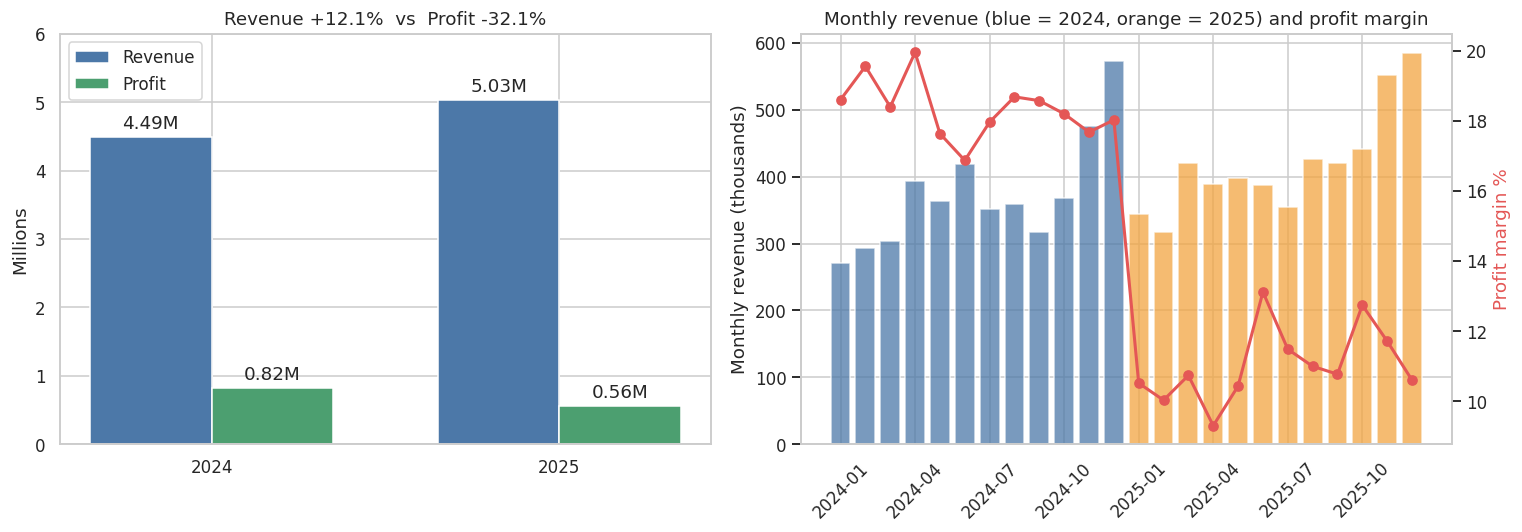

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# (a) Annual comparison
yr = df.groupby("Year")[["Revenue", "Profit"]].sum() / 1e6
x = np.arange(2); w = 0.35
b1 = axes[0].bar(x - w/2, yr["Revenue"], w, color=BLUE, label="Revenue")
b2 = axes[0].bar(x + w/2, yr["Profit"], w, color=GREEN, label="Profit")
axes[0].bar_label(b1, fmt="%.2fM", padding=3); axes[0].bar_label(b2, fmt="%.2fM", padding=3)
axes[0].set_xticks(x); axes[0].set_xticklabels(["2024", "2025"]); axes[0].set_ylabel("Millions")
rev_g = (yr.loc[2025, "Revenue"] / yr.loc[2024, "Revenue"] - 1) * 100
prof_g = (yr.loc[2025, "Profit"] / yr.loc[2024, "Profit"] - 1) * 100
axes[0].set_ylim(0, 6); axes[0].set_title(f"Revenue {rev_g:+.1f}%  vs  Profit {prof_g:+.1f}%"); axes[0].legend(loc="upper left")

# (b) Monthly revenue (bars) and profit margin % (line)
mon = df.groupby("YearMonth").agg(Revenue=("Revenue", "sum"), Profit=("Profit", "sum"))
mon["Margin"] = mon["Profit"] / mon["Revenue"] * 100
idx = mon.index.astype(str)
axes[1].bar(idx, mon["Revenue"] / 1e3, color=[BLUE if i.startswith("2024") else ORANGE for i in idx], alpha=0.75)
axes[1].set_ylabel("Monthly revenue (thousands)")
axes[1].set_xticks(range(0, len(idx), 3)); axes[1].set_xticklabels(idx[::3], rotation=45)
ax2 = axes[1].twinx(); ax2.plot(idx, mon["Margin"], color=RED, marker="o", lw=2); ax2.set_ylabel("Profit margin %", color=RED); ax2.grid(False)
axes[1].set_title("Monthly revenue (blue = 2024, orange = 2025) and profit margin")
plt.tight_layout(); plt.show()

### Visualisation 2 — Profit Bridge: Where Did the Profit Go?

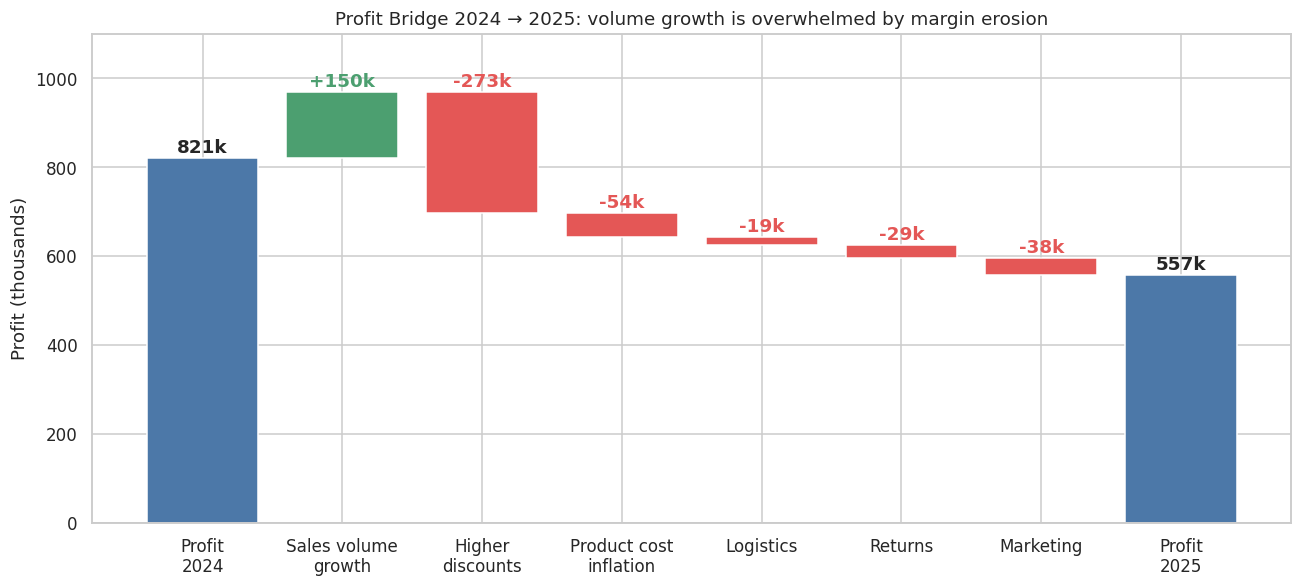

In [26]:
steps = [("Profit 2024", pl.loc["Profit", 2024])] + list(bridge.items()) + [("Profit 2025", pl.loc["Profit", 2025])]
labels = ["Profit\n2024", "Sales volume\ngrowth", "Higher\ndiscounts", "Product cost\ninflation", "Logistics", "Returns", "Marketing", "Profit\n2025"]

fig, ax = plt.subplots(figsize=(12, 5.5))
running = 0
for i, (name, val) in enumerate(steps):
    if i == 0 or i == len(steps) - 1:
        ax.bar(i, val / 1e3, color=BLUE); top = val / 1e3
        ax.text(i, top + 12, f"{val/1e3:,.0f}k", ha="center", fontweight="bold")
        running = val
    else:
        color = GREEN if val >= 0 else RED
        ax.bar(i, val / 1e3, bottom=running / 1e3, color=color)
        ypos = (running + max(val, 0)) / 1e3
        ax.text(i, ypos + 12, f"{val/1e3:+,.0f}k", ha="center", fontweight="bold", color=color)
        running += val
ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels)
ax.set_ylabel("Profit (thousands)"); ax.set_title("Profit Bridge 2024 → 2025: volume growth is overwhelmed by margin erosion")
ax.axhline(0, color="black", lw=0.8); ax.set_ylim(0, 1100)
plt.tight_layout(); plt.show()

### Visualisation 3 — Products: High Revenue but Low Margin

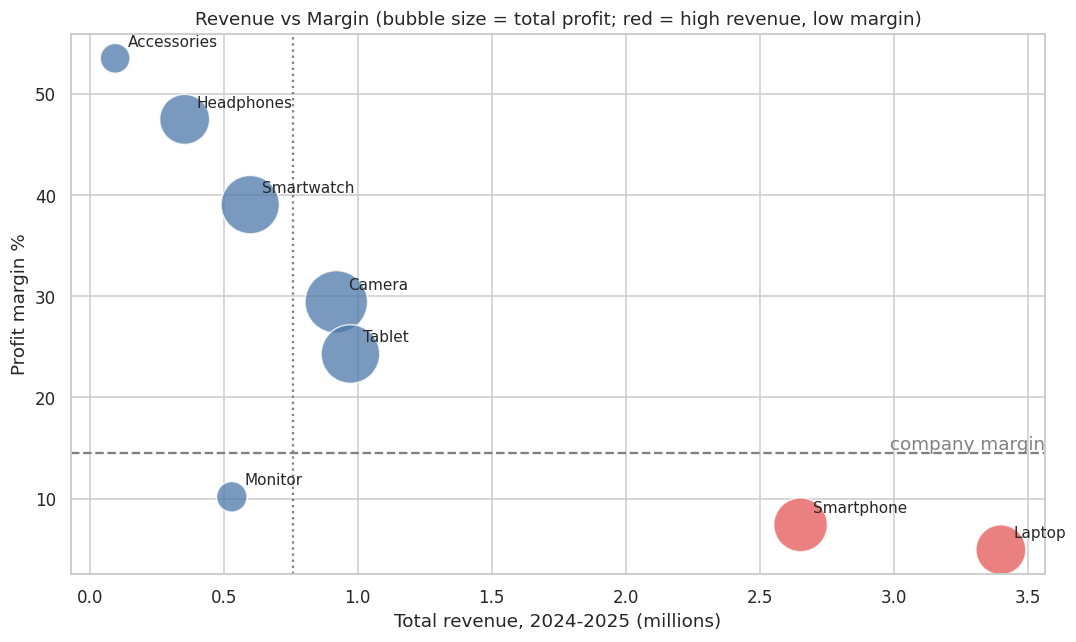

In [27]:
pt = prod_tbl.copy()
fig, ax = plt.subplots(figsize=(10, 6))
colors = [RED if flag else BLUE for flag in pt["High_Rev_Low_Margin"]]
ax.scatter(pt["Revenue"] / 1e6, pt["Margin_%"], s=pt["Profit"] / pt["Profit"].max() * 1600 + 80, c=colors, alpha=0.75, edgecolor="white")
for name, row in pt.iterrows():
    ax.annotate(name, (row["Revenue"] / 1e6, row["Margin_%"]), xytext=(8, 8), textcoords="offset points", fontsize=10)
ax.axhline(overall_margin, ls="--", color="gray"); ax.text(ax.get_xlim()[1], overall_margin + 0.4, " company margin", ha="right", color="gray")
ax.axvline(pt["Revenue"].median() / 1e6, ls=":", color="gray")
ax.set_xlabel("Total revenue, 2024-2025 (millions)"); ax.set_ylabel("Profit margin %")
ax.set_title("Revenue vs Margin (bubble size = total profit; red = high revenue, low margin)")
plt.tight_layout(); plt.show()

### Visualisation 4 — Effect of Discounts on Profitability

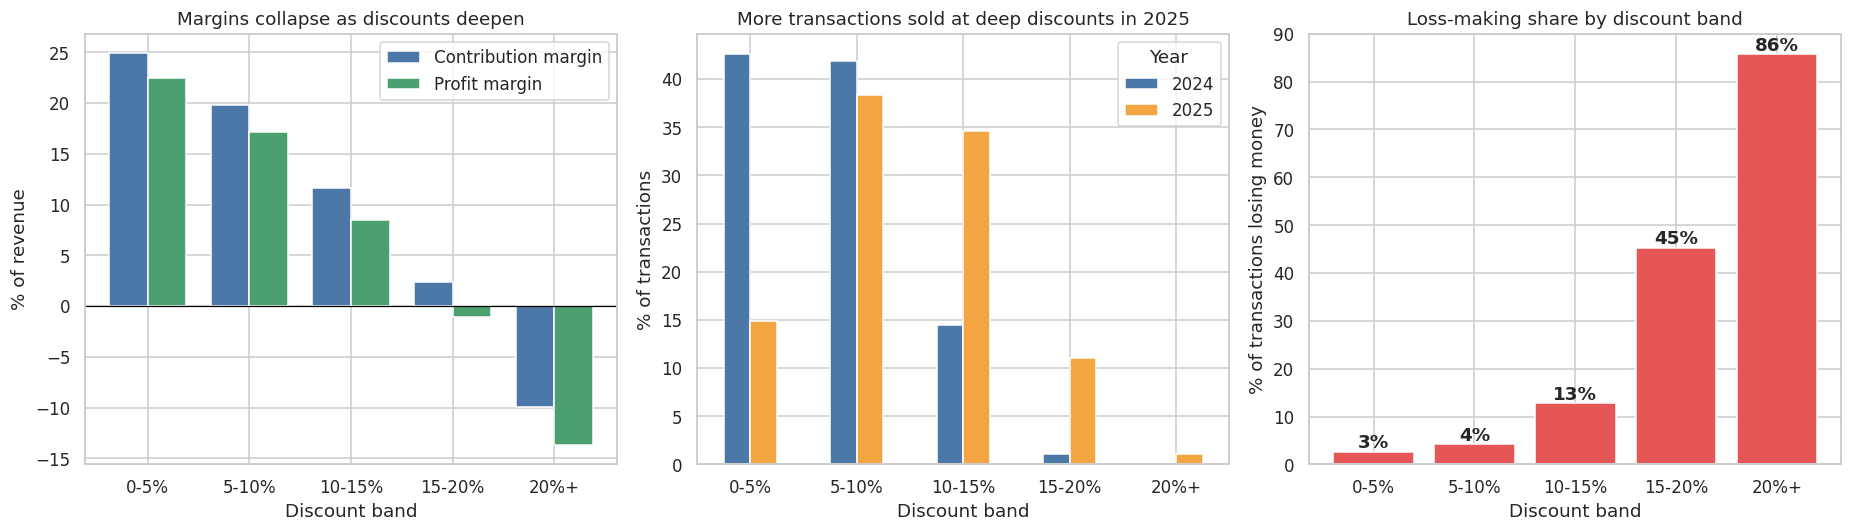

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# (a) Contribution margin and profit margin by discount band
x = np.arange(len(disc_tbl)); w = 0.38
axes[0].bar(x - w/2, disc_tbl["Contribution_Margin_%"], w, color=BLUE, label="Contribution margin")
axes[0].bar(x + w/2, disc_tbl["Profit_Margin_%"], w, color=GREEN, label="Profit margin")
axes[0].set_xticks(x); axes[0].set_xticklabels(disc_tbl.index); axes[0].axhline(0, color="black", lw=0.8)
axes[0].set_xlabel("Discount band"); axes[0].set_ylabel("% of revenue"); axes[0].set_title("Margins collapse as discounts deepen"); axes[0].legend()

# (b) Discount mix shift 2024 vs 2025
mixd = df.groupby(["Year", "Discount_Band"], observed=True).size().unstack(0)
mixd = mixd / mixd.sum() * 100
mixd.plot(kind="bar", ax=axes[1], color=[BLUE, ORANGE], rot=0)
axes[1].set_xlabel("Discount band"); axes[1].set_ylabel("% of transactions"); axes[1].set_title("More transactions sold at deep discounts in 2025")

# (c) Loss-making share by discount band
axes[2].bar(disc_tbl.index.astype(str), disc_tbl["Loss_Making_Share"], color=RED)
for i, v in enumerate(disc_tbl["Loss_Making_Share"]): axes[2].text(i, v + 0.8, f"{v:.0f}%", ha="center", fontweight="bold")
axes[2].set_xlabel("Discount band"); axes[2].set_ylabel("% of transactions losing money"); axes[2].set_title("Loss-making share by discount band")
plt.tight_layout(); plt.show()

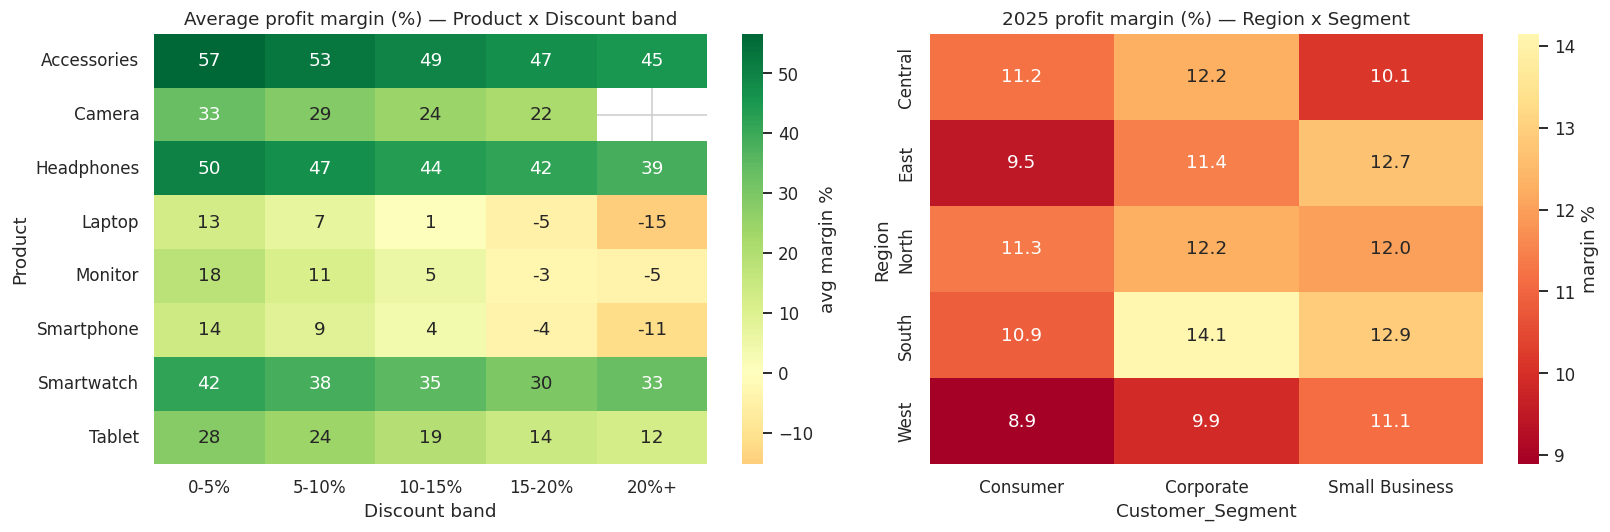

In [29]:
# Bonus charts: product x discount margin heatmap, and region x segment margin heatmap
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.heatmap(heat, annot=True, fmt=".0f", cmap="RdYlGn", center=0, ax=axes[0], cbar_kws={"label": "avg margin %"})
axes[0].set_title("Average profit margin (%) — Product x Discount band"); axes[0].set_xlabel("Discount band")
sns.heatmap(m25, annot=True, fmt=".1f", cmap="RdYlGn", center=overall_margin, ax=axes[1], cbar_kws={"label": "margin %"})
axes[1].set_title("2025 profit margin (%) — Region x Segment")
plt.tight_layout(); plt.show()

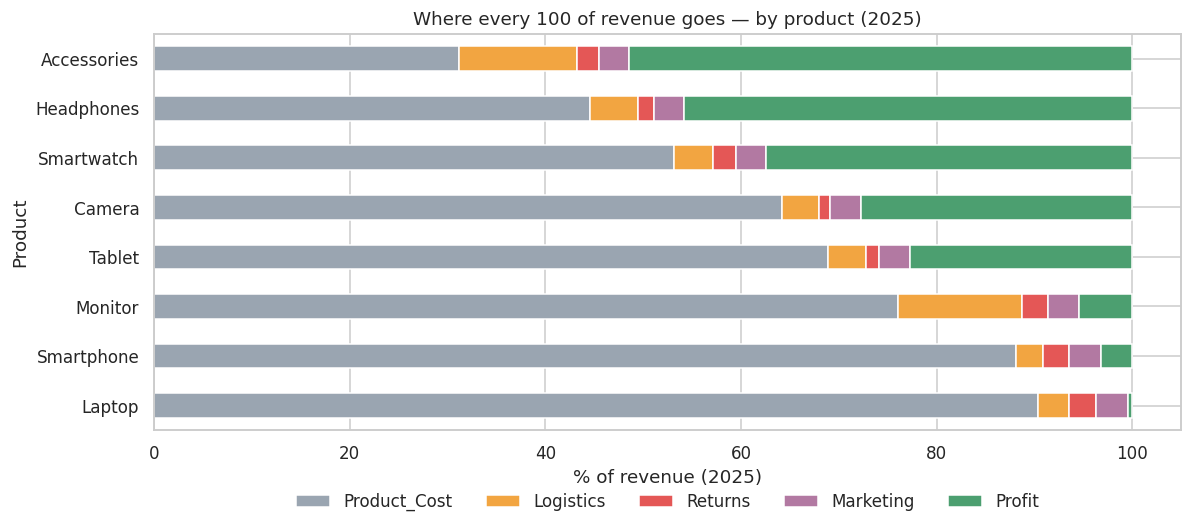

In [30]:
# Bonus chart: cost lines as % of revenue by product (2025) — where do returns and logistics bite?
c25 = d25.groupby("Product").agg(Revenue=("Revenue", "sum"), Product_Cost=("Product_Cost", "sum"), Logistics=("Logistics_Cost", "sum"),
                                 Returns=("Return_Cost", "sum"), Marketing=("Marketing_Expenditure", "sum"), Profit=("Profit", "sum"))
pct = c25[["Product_Cost", "Logistics", "Returns", "Marketing", "Profit"]].div(c25["Revenue"], axis=0) * 100
pct = pct.loc[prod_tbl.sort_values("Margin_%").index]
pct.plot(kind="barh", stacked=True, figsize=(11, 5), color=[GREY, ORANGE, RED, "#B279A2", GREEN])
plt.xlabel("% of revenue (2025)"); plt.title("Where every 100 of revenue goes — by product (2025)")
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=5, frameon=False); plt.tight_layout(); plt.show()

## 8. Random Forest Model — Predicting Loss-Making Transactions
**Goal:** predict whether a transaction will be **loss-making** (Profit < 0) using only information available **when the deal is priced**: product, region, customer segment, sales value, discount, marketing spend and month. A model like this could flag risky deals *before* the discount is approved.

⚠️ **Data-leakage note:** `Profit`, `Revenue`, `Product_Cost` and `Contribution` are excluded (they are the answer or almost determine it), and so are `Return_Cost` and `Logistics_Cost`, which are only known after the sale is shipped or returned.

In [31]:
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score,
                             confusion_matrix, classification_report, roc_curve, precision_recall_curve, ConfusionMatrixDisplay)

feat_cat = ["Product", "Region", "Customer_Segment"]
feat_num = ["Sales", "Discount", "Marketing_Expenditure", "Month"]

model_df = df.copy()
model_df["Marketing_Rate"] = model_df["Marketing_Expenditure"] / model_df["Sales"]      # marketing as a share of sales
feat_num = feat_num + ["Marketing_Rate"]

X = pd.get_dummies(model_df[feat_cat + feat_num], columns=feat_cat)
y = model_df["Loss_Making"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Loss-making share  train: {:.1f}%   test: {:.1f}%".format(y_train.mean() * 100, y_test.mean() * 100))

Train: (6400, 21) | Test: (1600, 21)
Loss-making share  train: 9.1%   test: 9.1%


In [32]:
# Tune the Random Forest with 5-fold cross-validation (ROC-AUC, because loss-making deals are a minority class)
param_grid = {"n_estimators": [200, 400], "max_depth": [6, 10, None], "min_samples_leaf": [2, 5, 10]}
grid = GridSearchCV(
    RandomForestClassifier(random_state=42, class_weight="balanced_subsample", n_jobs=-1),
    param_grid, cv=StratifiedKFold(5, shuffle=True, random_state=42), scoring="roc_auc", n_jobs=-1)
grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best CV ROC-AUC: {:.3f}".format(grid.best_score_))
rf = grid.best_estimator_      # the trained Random Forest model

Best parameters: {'max_depth': None, 'min_samples_leaf': 5, 'n_estimators': 200}
Best CV ROC-AUC: 0.906


### 8.1 Model Evaluation

In [33]:
y_pred = rf.predict(X_test)
y_prob = rf.predict_proba(X_test)[:, 1]

results = pd.Series({
    "Accuracy": accuracy_score(y_test, y_pred), "Precision": precision_score(y_test, y_pred),
    "Recall": recall_score(y_test, y_pred), "F1-score": f1_score(y_test, y_pred),
    "ROC-AUC": roc_auc_score(y_test, y_prob), "PR-AUC": average_precision_score(y_test, y_prob)}).round(3)
print("=== TEST SET PERFORMANCE ===")
print(results)
print("\n=== CLASSIFICATION REPORT ===")
print(classification_report(y_test, y_pred, target_names=["Profitable", "Loss-making"]))
print(f"Baseline accuracy (always 'Profitable'): {1 - y_test.mean():.3f}  |  Baseline PR-AUC (random): {y_test.mean():.3f}")

cv_auc = cross_val_score(rf, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=1), scoring="roc_auc")
print(f"5-fold CV ROC-AUC on the full data: {cv_auc.mean():.3f} ± {cv_auc.std():.3f}")

=== TEST SET PERFORMANCE ===
Accuracy     0.895
Precision    0.441
Recall       0.593
F1-score     0.506
ROC-AUC      0.908
PR-AUC       0.550
dtype: float64

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

  Profitable       0.96      0.93      0.94      1455
 Loss-making       0.44      0.59      0.51       145

    accuracy                           0.90      1600
   macro avg       0.70      0.76      0.72      1600
weighted avg       0.91      0.90      0.90      1600

Baseline accuracy (always 'Profitable'): 0.909  |  Baseline PR-AUC (random): 0.091
5-fold CV ROC-AUC on the full data: 0.907 ± 0.005


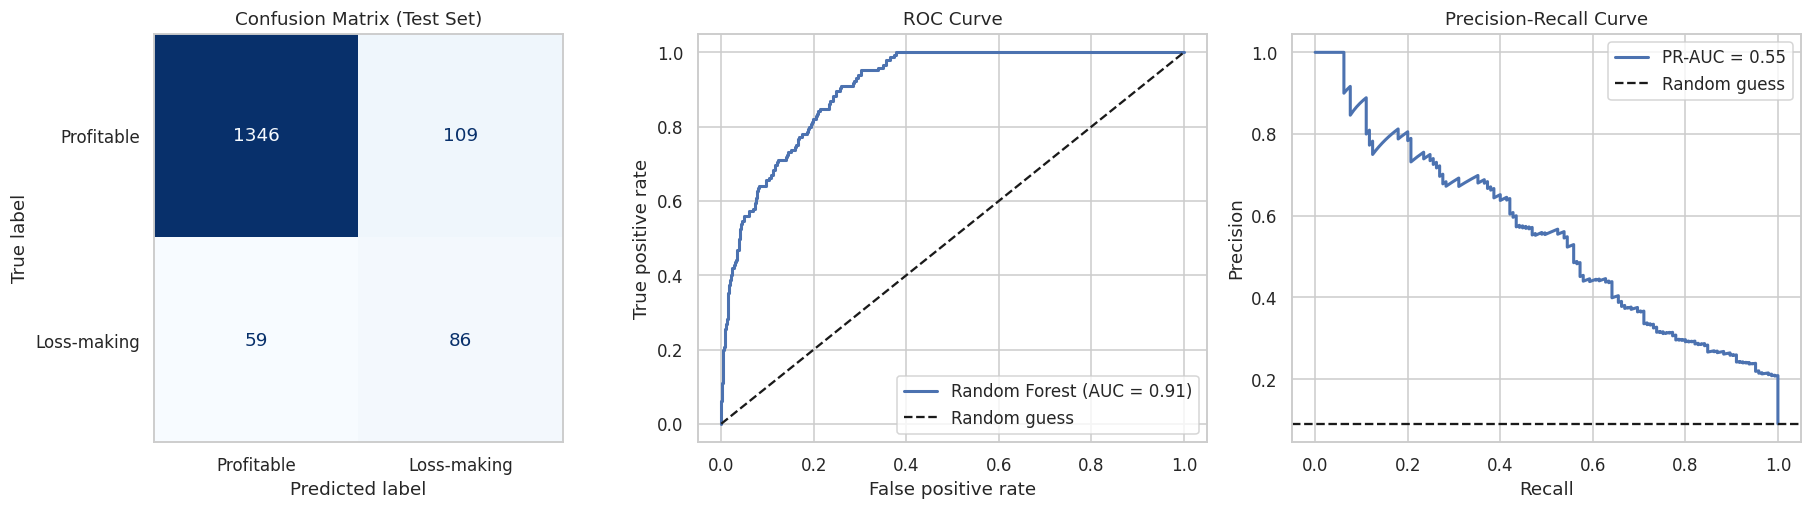

In [34]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=["Profitable", "Loss-making"]).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Confusion Matrix (Test Set)"); axes[0].grid(False)

fpr, tpr, _ = roc_curve(y_test, y_prob)
axes[1].plot(fpr, tpr, lw=2, label=f"Random Forest (AUC = {roc_auc_score(y_test, y_prob):.2f})"); axes[1].plot([0, 1], [0, 1], "k--", label="Random guess")
axes[1].set_xlabel("False positive rate"); axes[1].set_ylabel("True positive rate"); axes[1].set_title("ROC Curve"); axes[1].legend()

prec, rec, _ = precision_recall_curve(y_test, y_prob)
axes[2].plot(rec, prec, lw=2, label=f"PR-AUC = {average_precision_score(y_test, y_prob):.2f}")
axes[2].axhline(y_test.mean(), ls="--", color="k", label="Random guess")
axes[2].set_xlabel("Recall"); axes[2].set_ylabel("Precision"); axes[2].set_title("Precision-Recall Curve"); axes[2].legend()
plt.tight_layout(); plt.show()

In [35]:
# Robustness check: train on 2024 only, test on 2025 (does the model still work when the business changes?)
tr, te = (model_df["Year"] == 2024), (model_df["Year"] == 2025)
rf_time = RandomForestClassifier(**{k: v for k, v in grid.best_params_.items()}, random_state=42, class_weight="balanced_subsample", n_jobs=-1)
rf_time.fit(X[tr], y[tr])
p_time = rf_time.predict_proba(X[te])[:, 1]
print("Train on 2024 -> test on 2025")
print("  ROC-AUC: {:.3f}   PR-AUC: {:.3f}   Recall: {:.3f}   Precision: {:.3f}".format(
    roc_auc_score(y[te], p_time), average_precision_score(y[te], p_time),
    recall_score(y[te], p_time > 0.5), precision_score(y[te], p_time > 0.5)))

Train on 2024 -> test on 2025
  ROC-AUC: 0.884   PR-AUC: 0.504   Recall: 0.465   Precision: 0.515


### 8.2 What makes a deal lose money? (Feature Importance and Discount Sensitivity)

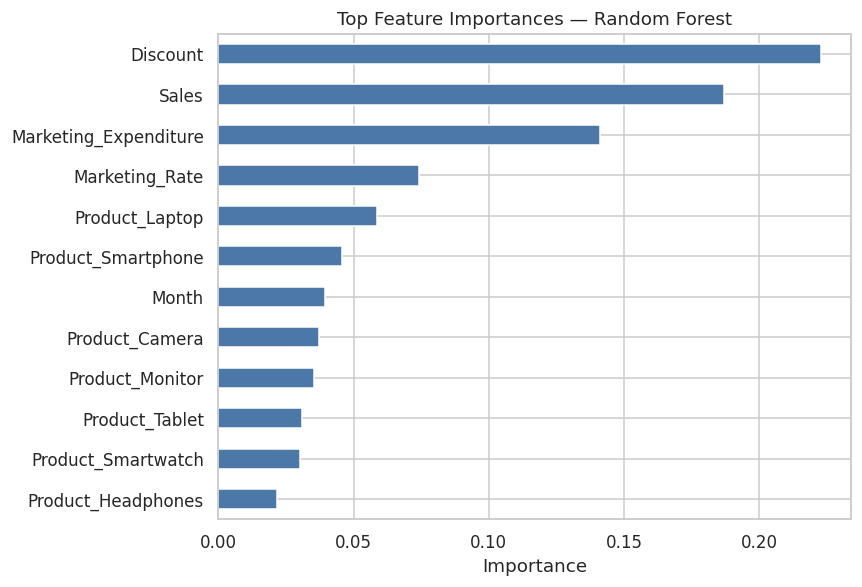

Discount                 0.223
Sales                    0.187
Marketing_Expenditure    0.141
Marketing_Rate           0.074
Product_Laptop           0.059
Product_Smartphone       0.046
Month                    0.039
Product_Camera           0.037
Product_Monitor          0.035
Product_Tablet           0.031
dtype: float64


In [36]:
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
plt.figure(figsize=(8, 5.5))
imp.head(12).sort_values().plot(kind="barh", color=BLUE)
plt.title("Top Feature Importances — Random Forest"); plt.xlabel("Importance"); plt.tight_layout(); plt.show()
print(imp.head(10).round(3))

Average predicted probability (%) that a 2025 deal loses money if it is sold at a given discount:
     Laptop  Smartphone  Monitor  Tablet  Smartwatch  Accessories
0%     26.8        28.4     18.7     3.4         1.1          0.2
5%     33.6        30.2     21.1     3.9         1.0          0.1
10%    43.9        34.7     28.5     6.0         1.5          0.2
15%    80.3        67.0     59.8    16.9         7.5          1.0
20%    87.0        79.7     69.3    24.8        17.8          6.3


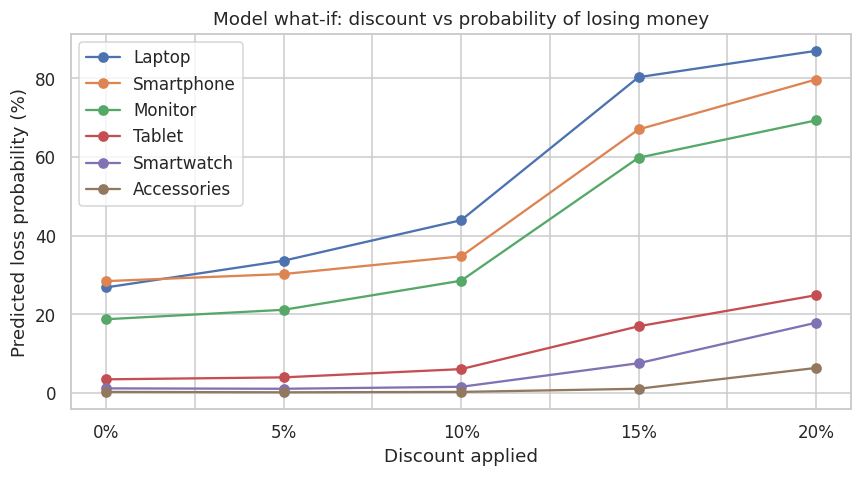

In [37]:
# What-if (partial dependence): take the REAL 2025 deals of each product, set every deal's discount to a given level,
# and average the model's predicted probability of losing money
levels = [0.00, 0.05, 0.10, 0.15, 0.20]
d25_idx = model_df.index[model_df["Year"] == 2025]
whatif = {}
for p in ["Laptop", "Smartphone", "Monitor", "Tablet", "Smartwatch", "Accessories"]:
    base_rows = X.loc[d25_idx][X.loc[d25_idx, f"Product_{p}"] == 1]
    probs = []
    for d in levels:
        tmp = base_rows.copy(); tmp["Discount"] = d
        probs.append(rf.predict_proba(tmp)[:, 1].mean() * 100)
    whatif[p] = probs
whatif = pd.DataFrame(whatif, index=[f"{int(d*100)}%" for d in levels]).round(1)
print("Average predicted probability (%) that a 2025 deal loses money if it is sold at a given discount:")
print(whatif)

whatif.plot(marker="o", figsize=(8, 4.5)); plt.ylabel("Predicted loss probability (%)"); plt.xlabel("Discount applied")
plt.title("Model what-if: discount vs probability of losing money"); plt.tight_layout(); plt.show()

In [38]:
# Business use: risk-score deals and see how many losses the top-risk group captures
scored = pd.DataFrame({"Actual": y_test.values, "Risk": y_prob}).sort_values("Risk", ascending=False)
top = scored.head(int(len(scored) * 0.15))
print(f"Reviewing only the top 15% riskiest deals catches {top['Actual'].sum() / scored['Actual'].sum() * 100:.0f}% of all loss-making deals "
      f"(loss rate in that group: {top['Actual'].mean() * 100:.0f}% vs {scored['Actual'].mean() * 100:.0f}% overall).")

Reviewing only the top 15% riskiest deals catches 66% of all loss-making deals (loss rate in that group: 40% vs 9% overall).


## 9. Quantifying the Fixes (Scenario Estimates)
Rough, data-based estimates of what each action could recover, using 2025 transactions. These are **estimates, not forecasts** — they ignore secondary effects (e.g. fewer returns from lower discounts).

1209 deals (28% of 2025 transactions) carry a discount above 10% on the three low-margin products
  Profit of those deals in 2025: -13,315

Profit lost vs 2024: 263,207
                                                 Profit_Uplift  \
A. Cap discounts at 10% (3 low-margin products)        88969.0   
B. Cut return costs by 25%                             29546.0   
C. Marketing back to 2024 % of sales                   38437.0   
D. Save 10% of logistics cost                          19757.0   

                                                 Share_of_profit_gap_%  
A. Cap discounts at 10% (3 low-margin products)                   33.8  
B. Cut return costs by 25%                                        11.2  
C. Marketing back to 2024 % of sales                              14.6  
D. Save 10% of logistics cost                                      7.5  

All four together: 176,709  (67% of the profit gap)   -> 2025 profit would be about 734,061


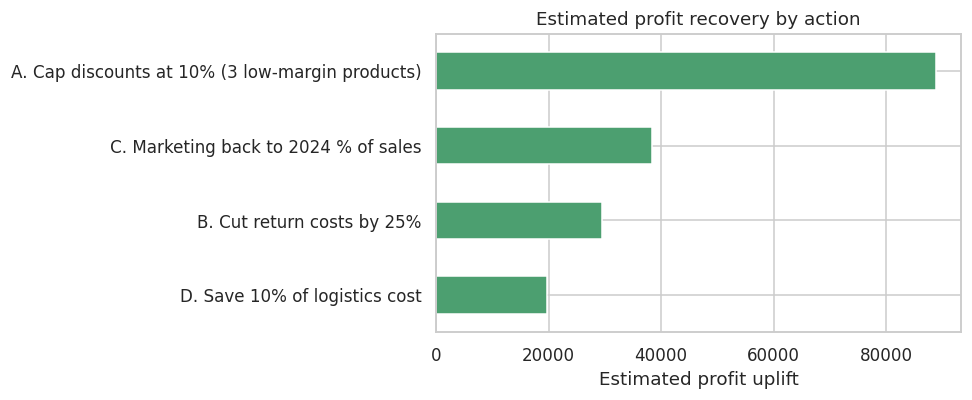

In [39]:
d25 = df[df["Year"] == 2025].copy()
gap = pl.loc["Profit", 2024] - pl.loc["Profit", 2025]          # profit lost vs last year

# A) Cap discounts at 10% on Laptop / Smartphone / Monitor; assume 30% of the affected deals walk away
hi = d25[d25["Product"].isin(["Laptop", "Smartphone", "Monitor"]) & (d25["Discount"] > 0.10)]
kept_gain = 0.70 * (hi["Sales"] * (hi["Discount"] - 0.10)).sum()          # kept deals: pay less discount
lost_effect = 0.30 * (-hi["Profit"]).sum()                                 # walked-away deals: profit (or loss) disappears
A = kept_gain + lost_effect
print(f"{len(hi)} deals ({len(hi)/len(d25)*100:.0f}% of 2025 transactions) carry a discount above 10% on the three low-margin products")
print(f"  Profit of those deals in 2025: {hi['Profit'].sum():,.0f}")

# B) Cut return costs by 25% (returns policy, quality checks, smaller discount-driven impulse buys)
B = 0.25 * d25["Return_Cost"].sum()

# C) Bring marketing back to its 2024 share of sales
mkt_rate24 = pl.loc["Marketing", 2024] / pl.loc["Sales", 2024]
C = d25["Marketing_Expenditure"].sum() - mkt_rate24 * d25["Sales"].sum()

# D) Save 10% of logistics cost (consolidated shipments, cheaper carriers on Monitor / Accessories / Central)
D = 0.10 * d25["Logistics_Cost"].sum()

scen = pd.Series({"A. Cap discounts at 10% (3 low-margin products)": A, "B. Cut return costs by 25%": B,
                  "C. Marketing back to 2024 % of sales": C, "D. Save 10% of logistics cost": D})
scen_tbl = pd.DataFrame({"Profit_Uplift": scen.round(0)})
scen_tbl["Share_of_profit_gap_%"] = (scen / gap * 100).round(1)
print("\nProfit lost vs 2024: {:,.0f}".format(gap))
print(scen_tbl)
print("\nAll four together: {:,.0f}  ({:.0f}% of the profit gap)   -> 2025 profit would be about {:,.0f}".format(
    scen.sum(), scen.sum() / gap * 100, pl.loc["Profit", 2025] + scen.sum()))

scen.sort_values().plot(kind="barh", figsize=(9, 3.8), color=GREEN)
plt.xlabel("Estimated profit uplift"); plt.title("Estimated profit recovery by action"); plt.tight_layout(); plt.show()

## 10. Practical Action Plan

Estimated profit recovery is based on 2025 transactions (Section 9). The profit lost versus 2024 is **≈ 263k**.

| Priority | Action | Data behind it | Estimated impact |
|---|---|---|---|
| **1 – High** | **Discount governance:** cap discounts at **10%** on Laptops, Smartphones and Monitors; require manager approval above 10% and finance approval above 15%; never discount these products below break-even | 1,209 deals (28% of 2025 transactions) at >10% off on these products earned **−13k in total**; margin turns negative at 15–20% | **≈ +89k** (34% of the gap), assuming 30% of affected deals walk away |
| **2 – High** | **Protect margin on Laptops and Smartphones:** renegotiate supplier prices, bundle high-margin Accessories/Headphones (50%+ margin) with laptops instead of cutting price | Laptop margin 10.1% → 0.4%; product cost ratio rose 0.95 pp (−54k) | Part of the remaining gap; a 1% cost saving on laptops and phones ≈ +28k |
| **3 – Medium** | **Marketing efficiency:** return to the 2024 spend level (2.2% of sales), starting with the West (3.1% of revenue); track return on each campaign | Marketing +55% while revenue grew 12% | **≈ +38k** (15% of the gap) |
| **4 – Medium** | **Returns programme:** tighten return policy on heavily discounted items, fix Smartwatch quality/fit issues, improve product information to reduce returns | Return rate 9.7% → 11.6%; 18.4% on deals with 20%+ discount; Smartwatch 16.3% | **≈ +30k** if returns cost falls 25% |
| **5 – Medium** | **Logistics optimisation:** minimum order values or shipping fees on Monitors/Accessories, consolidated shipments, carrier renegotiation for the Central region | Logistics = 11–12% of revenue on Monitors/Accessories; Central 4.4% | **≈ +20k** for a 10% saving |
| **6 – Medium** | **Deploy the Random Forest as a deal-risk screen:** score every quote, flag the top 15% riskiest deals for review before the discount is approved | Top 15% of scored deals contain 66% of losses; ROC-AUC 0.91 (0.88 on unseen 2025 data) | Prevents loss-making deals before they happen |
| **7 – Medium** | **Segment/region pricing rules:** differentiate discounts for Consumers and the West, where discounts are deepest and margins lowest | West margin 9.7%, Consumer margin 10.3% | Supports actions 1 and 3 |
| **8 – Low** | **Monitor profit, not sales:** replace revenue targets with contribution-margin targets; monthly dashboard by product, discount band and region; review the model quarterly | Revenue rose 12% and hid a 32% profit fall | Early warning of the next margin squeeze |
| **9 – Data** | **Collect more data:** units sold, discount approval reason, customer ID, campaign ID and return reason | Needed for price elasticity and campaign ROI | Better modelling and root-cause analysis |

**Combined effect of actions 1, 3, 4 and 5:** about **+177k**, recovering roughly **two-thirds of the lost profit** (2025 profit ≈ 734k vs 820k in 2024) even before renegotiating supplier costs.